# STM simulator demo -- from raw Nanonis files

`STMMicroscope.from_nanonis` builds the simulator straight from the raw
files, no conversion step:

| variant | call | image (`scan_image()`) | spectroscopy |
|---|---|---|---|
| **1. `.sxm` + `.3ds`** | `STMMicroscope.from_nanonis(file_3ds=..., file_sxm=...)` | `.sxm` `Z forward` (512x512) | `.3ds` grid |
| **2. `.3ds` only** | `STMMicroscope.from_nanonis(file_3ds=...)` | `.3ds` grid `Topography` (180x180) | `.3ds` grid |

Both use the bundled `mexpsimu/data/stm_data/large_area/` files. Reading raw
files needs the gnganesh99/SciFiReaders fork; run from the project's
environment (`pip install -e .`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import mexpsimu
from mexpsimu import STMMicroscope

DATA_DIR = mexpsimu.default_stm_data_dir() / "large_area"
SXM_FILE = DATA_DIR / "EnZn2As2122.sxm"
GRID_FILE = DATA_DIR / "EuZn2As2008.3ds"
print(SXM_FILE.name, GRID_FILE.name)


def extent(channel):
    """imshow extent from a channel's (Y, X) axes, in nm."""
    y, x = channel.axes[0].values, channel.axes[1].values
    return [x.min(), x.max(), y.min(), y.max()]


def show(scope, points_nm):
    """Plot scan_image() with the given tip positions, and the LIX 1 omega
    spectrum taken at each one."""
    z = scope.scan_image()
    fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
    im = axs[0].imshow((z - np.nanmin(z)) * 1e9, origin="lower",
                       extent=extent(scope.dataset.topography[scope.default_image_channel]), cmap="afmhot")
    fig.colorbar(im, ax=axs[0], label="height (nm, relative)")
    axs[0].set_title(f'scan_image() -- "{scope.default_image_channel}"  {z.shape[1]}x{z.shape[0]} px')
    axs[0].set_xlabel("X (nm)")
    axs[0].set_ylabel("Y (nm)")
    for (x, y), color in zip(points_nm, ["tab:blue", "cyan", "lime"]):
        bias, didv = scope.spectroscopy(x, y, channel="LIX 1 omega")
        p = scope.position
        axs[1].plot(bias, didv * 1e12, color=color, label=f"({p.x_nm:.0f}, {p.y_nm:.0f}) nm")
        axs[0].plot(p.x_nm, p.y_nm, "+", color=color, markersize=14, markeredgewidth=2.5)
    axs[1].set_xlabel("bias (V)")
    axs[1].set_ylabel("LIX 1 omega (pA)")
    axs[1].set_title("spectroscopy() at the marked points")
    axs[1].legend()
    fig.tight_layout()
    plt.show()


POINTS_NM = [(40.0, 120.0), (110.0, 120.0), (200.0, 120.0)]  # upper terrace, step region, lower terrace

EnZn2As2122.sxm EuZn2As2008.3ds


## 1. `.sxm` + `.3ds`

The `.sxm` scan gives the high-resolution image channels; the `.3ds` grid
gives the spectroscopy channels (and its own `Topography`, also available
as an image channel).

In [2]:
scope = STMMicroscope.from_nanonis(file_3ds=GRID_FILE, file_sxm=SXM_FILE)

print(scope)
print("image channels:       ", scope.list_channels())
print("default image channel:", scope.default_image_channel)
print("spectroscopy channels:", scope.list_spectroscopy_channels())

STMMicroscope(dataset='EuZn2As2008', has_topography=True, spectroscopy_shape=(180, 180), measurement_noise=0.0, position=STMTipPosition(row=90, col=90, x_nm=125.0, y_nm=125.0))
image channels:        ['Z forward', 'Z backward', 'Current forward', 'Current backward', 'LIX_1_omega forward', 'LIX_1_omega backward', 'LIY_1_omega forward', 'LIY_1_omega backward', 'Topography']
default image channel: Z forward
spectroscopy channels: ['Current', 'LIX 1 omega', 'LIY 1 omega']


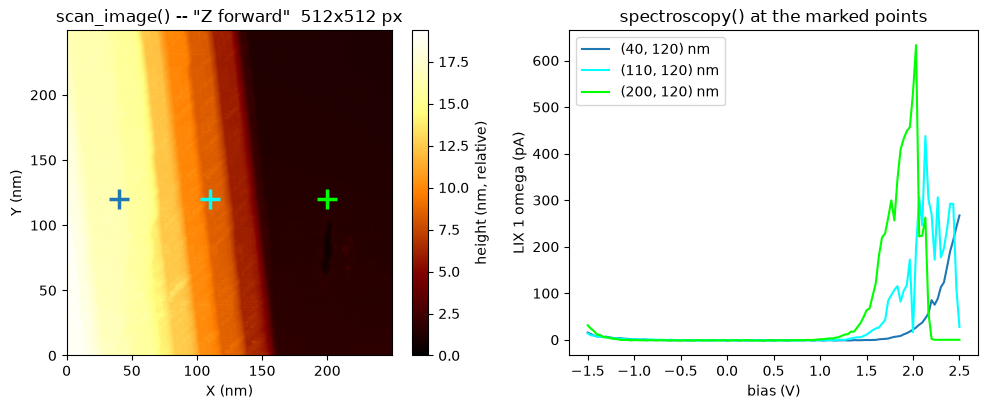

In [3]:
show(scope, POINTS_NM)

## 2. `.3ds` only

Without an `.sxm`, the `.3ds` grid's `Topography` (the Z-controller height at
each grid pixel) is the image. Spectroscopy is identical to variant 1 -- the
same `.3ds` grid.

In [4]:
grid_scope = STMMicroscope.from_nanonis(file_3ds=GRID_FILE)

print(grid_scope)
print("image channels:       ", grid_scope.list_channels())
print("default image channel:", grid_scope.default_image_channel)
print("spectroscopy channels:", grid_scope.list_spectroscopy_channels())

STMMicroscope(dataset='EuZn2As2008', has_topography=True, spectroscopy_shape=(180, 180), measurement_noise=0.0, position=STMTipPosition(row=90, col=90, x_nm=125.0, y_nm=125.0))
image channels:        ['Topography']
default image channel: Topography
spectroscopy channels: ['Current', 'LIX 1 omega', 'LIY 1 omega']


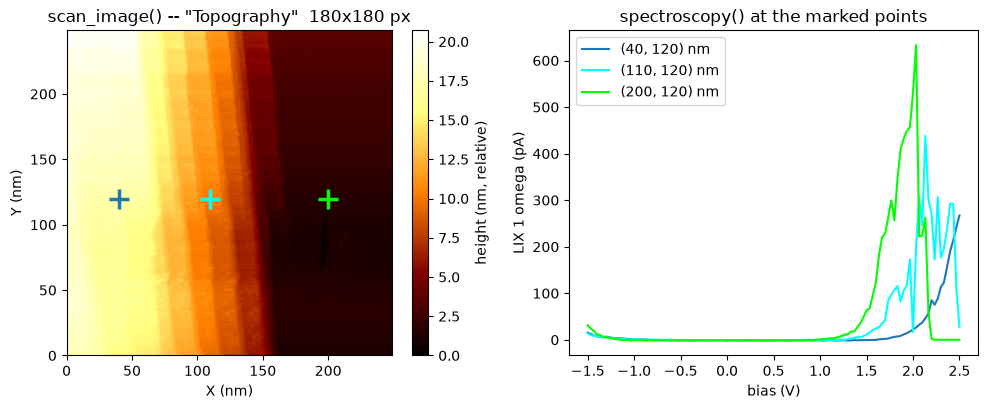

same spectrum in both variants: True


In [5]:
show(grid_scope, POINTS_NM)

# same tip position -> same spectrum in both variants
bias, a = scope.spectroscopy(110.0, 120.0)
_, b = grid_scope.spectroscopy(110.0, 120.0)
print("same spectrum in both variants:", np.array_equal(a, b))

## Result

Both variants expose the same `scan_image()` / `move_tip()` /
`spectroscopy()` interface; they differ only in the image channels (and so
the default `scan_image()`).

`STMMicroscope("large_area")` loads the same combined data from the
pre-converted `large_area/sidpy/*.h5` instead, which doesn't need the
SciFiReaders fork at runtime.